# IND320 - Project 4: Data to Decision

- **GitHub repository:** https://github.com/giorgiocrupi/giorgiocrupi-ind320-project1
- **Streamlit app:** [LINK]
- **Video:** [LINK TO BE ADDED]

## Log
*(to be written at the end: what I did, problems and solutions, findings)*

## AI declaration
*(to be written at the end)*

## 1. Currency exchange rates from Norges Bank

Norges Bank publishes official exchange rates through an open SDMX API (no key needed).
A series is selected with a key such as `B.EUR+USD.NOK.SP`:
`B` = business-day frequency, `EUR+USD` = base currencies, `NOK` = quote currency, `SP` = spot rate.

The function below downloads the rates for any period, frequency and set of currencies,
and returns one column per currency with the price of **1 unit in NOK**.

In [2]:
import io
import requests
import pandas as pd
import plotly.express as px

# Base address of the Norges Bank exchange-rate data (EXR = exchange rates).
# {frequency} and {currencies} are filled in by the function.
NB_URL = "https://data.norges-bank.no/api/data/EXR/{frequency}.{currencies}.NOK.SP"


def download_exchange_rates(start_date, end_date, currencies=("EUR", "USD"), frequency="B"):
    """Download exchange rates against NOK from the Norges Bank API.

    start_date, end_date : period to download, as "YYYY-MM-DD" strings
    currencies           : base currencies, e.g. ("EUR", "USD")
    frequency            : "B" = business days, "M" = monthly, "A" = annual

    Returns a DataFrame with one row per date and one column per currency,
    containing the price of 1 unit of the currency in NOK.
    """
    # Build the series key, e.g. "B.EUR+USD.NOK.SP" ("+" selects several currencies at once)
    url = NB_URL.format(frequency=frequency, currencies="+".join(currencies))
    params = {
        "format": "csv",          # plain CSV text instead of the default Excel file
        "startPeriod": start_date,
        "endPeriod": end_date,
        "locale": "en",           # English labels and "." as decimal separator
    }
    response = requests.get(url, params=params, timeout=60)
    response.raise_for_status()   # stop with a clear error if the API does not answer correctly

    # Read the CSV text. sep=None lets pandas detect the separator (Norges Bank uses ";").
    raw = pd.read_csv(io.StringIO(response.text), sep=None, engine="python")

    # OBS_VALUE is the rate. Replace a possible decimal comma with a dot, then convert to numbers.
    values = pd.to_numeric(raw["OBS_VALUE"].astype(str).str.replace(",", "."), errors="coerce")
    # UNIT_MULT is the power of ten of the unit (0 = per 1 unit, 2 = per 100 units, e.g. JPY).
    # Dividing by 10**UNIT_MULT always gives the price of 1 unit.
    values = values / 10 ** raw["UNIT_MULT"].astype(int)

    # Long table (one row per date and currency) -> wide table (one column per currency)
    rates = (
        pd.DataFrame({
            "date": pd.to_datetime(raw["TIME_PERIOD"]),
            "currency": raw["BASE_CUR"],
            "nok": values.values,
        })
        .pivot(index="date", columns="currency", values="nok")
        .sort_index()
    )
    rates.columns.name = None   # remove the leftover "currency" label above the columns
    return rates

### Test of the function

Daily (business-day) EUR and USD rates for 2024, plus a monthly version of the same period
to show that the frequency can be changed.

In [3]:
# Daily rates (business days only: no values on weekends and Norwegian bank holidays)
rates_daily = download_exchange_rates("2024-01-01", "2024-12-31")
print(f"{len(rates_daily)} business days downloaded")
display(rates_daily.head())

# Monthly averages for the same period, to show the frequency parameter
rates_monthly = download_exchange_rates("2024-01-01", "2024-12-31", frequency="M")
display(rates_monthly)

# Interactive Plotly line chart: hover shows the exact value, drag to zoom
fig = px.line(
    rates_daily,
    labels={"value": "NOK per unit", "date": "Date", "variable": "Currency"},
    title="Exchange rates against NOK (Norges Bank, 2024)",
)
fig.show()

251 business days downloaded


,EUR,USD
date,,
2024-01-02,11.2815,10.2971
2024-01-03,11.3200,10.3672
2024-01-04,11.2845,10.3027
2024-01-05,11.3090,10.3553
2024-01-08,11.3620,10.3800


,EUR,USD
date,,
2024-01-01,11.3501,10.4083
2024-02-01,11.3843,10.5463
2024-03-01,11.5120,10.5857
2024-04-01,11.6828,10.8911
2024-05-01,11.5898,10.7199
2024-06-01,11.4178,10.6125
2024-07-01,11.7160,10.8038
2024-08-01,11.7895,10.7073
2024-09-01,11.7852,10.6121


## 2. Time zones in the four data sources

The forecasting model combines data from NVE (Magasinstatistikk), ENTSO-E, Open-Meteo and
Norges Bank. If the sources use different clocks, values can be shifted by one or two hours
(or even assigned to the wrong week). Norway uses CET (UTC+1) in winter and CEST (UTC+2) in
summer, so one day per year has 23 hours (last Sunday of March) and one has 25 hours
(last Sunday of October).

Each source is checked below with real data.

### 2.1 NVE Magasinstatistikk

The reservoir statistics are weekly and identified by ISO year and ISO week, with no time of day.
The API also returns a date field (`dato_Id`). We check which weekday this date falls on,
to know which day of the week the weekly value refers to.

In [4]:
import sys
sys.path.append("..")   # the notebook is in notebooks/, analysis.py is in the project folder
from analysis import load_reservoirs

reservoirs = load_reservoirs()

# dato_Id = date supplied by NVE; Date = Monday of the ISO week (the convention we used so far)
display(reservoirs[["dato_Id", "iso_aar", "iso_uke", "Date"]].head())

# Which weekday does NVE's own date fall on?
nve_dates = pd.to_datetime(reservoirs["dato_Id"])
print("Weekday of dato_Id:")
print(nve_dates.dt.day_name().value_counts())

,dato_Id,iso_aar,iso_uke,Date
0,2020-11-15,2020,46,2020-11-09
1,2011-08-28,2011,34,2011-08-22
2,1998-07-05,1998,27,1998-06-29
3,2011-03-27,2011,12,2011-03-21
4,2017-11-05,2017,44,2017-10-30


Weekday of dato_Id:
dato_Id
Sunday    14976
Name: count, dtype: int64


### 2.2 Open-Meteo

Open-Meteo returns hourly values in GMT (UTC) unless the `timezone` parameter is given.
We download three days around the switch to summer time (31 March 2024) for one point
(Trondheim), once in GMT and once in `Europe/Oslo`, and compare the timestamps.

In [5]:
OPENMETEO_URL = "https://archive-api.open-meteo.com/v1/archive"


def openmeteo_times(timezone):
    """Download three days of hourly temperature for Trondheim in the given time zone
    and return the timestamps together with the UTC offset reported by the API."""
    params = {
        "latitude": 63.43, "longitude": 10.39,
        "start_date": "2024-03-30", "end_date": "2024-04-01",   # 31 March = switch to summer time
        "hourly": "temperature_2m",
        "timezone": timezone,
    }
    response = requests.get(OPENMETEO_URL, params=params, timeout=60)
    response.raise_for_status()
    data = response.json()
    times = pd.to_datetime(data["hourly"]["time"])
    return times, data["utc_offset_seconds"]


for tz in ["GMT", "Europe/Oslo"]:
    times, offset = openmeteo_times(tz)
    print(f"timezone={tz}: offset reported = {offset / 3600:+.0f} h, {len(times)} values")
    # Number of hourly values per calendar day (a correct local clock has 23 on 31 March)
    print(pd.Series(1, index=times).groupby(times.date).size().to_string(), "\n")

timezone=GMT: offset reported = +0 h, 72 values
2024-03-30    24
2024-03-31    24
2024-04-01    24 

timezone=Europe/Oslo: offset reported = +1 h, 72 values
2024-03-30    24
2024-03-31    24
2024-04-01    24 



### 2.3 ENTSO-E

The ENTSO-E Transparency API works in UTC, and in Project 2 the flows were stored in MongoDB
with UTC timestamps. The example below shows what happens when hourly UTC data is converted
to Norwegian local time: the day of the switch to summer time contains only 23 hours.

In [6]:
# Three days of hourly UTC timestamps, starting at local midnight of 30 March (= 23:00 UTC)
utc_index = pd.date_range("2024-03-29 23:00", "2024-04-01 21:00", freq="h", tz="UTC")
oslo_index = utc_index.tz_convert("Europe/Oslo")   # time-zone aware conversion

print("Hours per local day after conversion to Europe/Oslo:")
print(pd.Series(1, index=oslo_index).groupby(oslo_index.date).size().to_string())
print("\nLocal clock around the switch:", list(oslo_index[25:28].strftime("%d %b %H:%M %Z")))

Hours per local day after conversion to Europe/Oslo:
2024-03-30    24
2024-03-31    23
2024-04-01    24

Local clock around the switch: ['31 Mar 01:00 CET', '31 Mar 03:00 CEST', '31 Mar 04:00 CEST']


### 2.4 Norges Bank

The exchange rates have a date but no time, and are only published on Norwegian business days.
We list the weekdays of 2024 that have no rate: these are Norwegian public holidays.

In [7]:
# All Monday-Friday dates of 2024 ("B" = business days in pandas, i.e. Monday to Friday)
weekdays_2024 = pd.date_range("2024-01-01", "2024-12-31", freq="B")
missing = weekdays_2024.difference(rates_daily.index)

print(f"Weekend days have no rates; {len(missing)} weekdays are also missing:")
print([d.strftime("%a %d %b") for d in missing])

Weekend days have no rates; 11 weekdays are also missing:
['Mon 01 Jan', 'Thu 28 Mar', 'Fri 29 Mar', 'Mon 01 Apr', 'Wed 01 May', 'Thu 09 May', 'Fri 17 May', 'Mon 20 May', 'Tue 24 Dec', 'Wed 25 Dec', 'Thu 26 Dec']


### 2.5 Findings and solution

| Source | Resolution | Time information | Finding |
|---|---|---|---|
| NVE Magasinstatistikk | weekly | ISO year + week, `dato_Id` | `dato_Id` is always the **Sunday** that ends the ISO week, so the filling rate is the status at the end of the week. So far each week was labelled with its **Monday** (`Date`). |
| ENTSO-E | hourly | UTC | Stored in MongoDB in UTC. Converted to Norwegian time, one day per year has 23 hours and one has 25. |
| Open-Meteo | hourly | GMT by default, or `timezone` | With `timezone=Europe/Oslo` the API returns one fixed UTC offset (+1 h) for the whole request and 24 values on 31 March, so values after the switch to summer time are one hour off the real Norwegian clock. |
| Norges Bank | business days | date only | No values on weekends and Norwegian public holidays. |

**Solution used in this project**

1. Download hourly data in **UTC** (ENTSO-E, Open-Meteo with `timezone=UTC`) and convert it with
   pandas `tz_convert("Europe/Oslo")`, which handles summer time correctly.
   `download_weather` in `analysis.py` already works this way.
2. Never mix time-zone aware and naive timestamps: convert to Norwegian local time first,
   then drop the time-zone information.
3. Bring all sources to the **resolution of the target variable** (weekly, as NVE): weeks run
   Monday–Sunday and are labelled with the Monday, as in the `Date` column of the reservoir data.
   The filling rate (measured on the Sunday) is then matched with the weather, flows and
   exchange rates of the same week. Missing days (weekends and holidays for Norges Bank)
   are simply left out of the weekly mean.

The helper function below implements step 2 and 3. It will be used to prepare the inputs
of the forecasting model.

In [8]:
def to_weekly(series, how="mean"):
    """Aggregate a daily or hourly series (or DataFrame) to weeks.

    Weeks run Monday-Sunday and are labelled with the Monday, the same convention as the
    `Date` column of the NVE reservoir data.
    how : "mean" (e.g. temperature, exchange rates) or "sum" (e.g. precipitation, energy)
    """
    s = series.copy()
    # Time-zone aware data (e.g. UTC) -> Norwegian local time (summer time handled by pandas),
    # then drop the time zone so it can be combined with the naive NVE dates
    if s.index.tz is not None:
        s.index = s.index.tz_convert("Europe/Oslo").tz_localize(None)
    # "W-MON" bins end on Mondays; closed/label="left" gives [Monday, next Monday) labelled by Monday
    weekly = s.resample("W-MON", closed="left", label="left")
    return weekly.sum() if how == "sum" else weekly.mean()


# Test: weekly mean of the daily exchange rates (holidays and weekends are just left out)
rates_weekly = to_weekly(rates_daily)
display(rates_weekly.head())

# The week labels are Mondays, the same weekdays as the NVE "Date" column
print("Weekday of the labels:", rates_weekly.index.day_name().unique().tolist())
print("Weekday of NVE Date:  ", reservoirs["Date"].dt.day_name().unique().tolist())

,EUR,USD
date,,
2024-01-01,11.29875,10.330575
2024-01-08,11.31326,10.329660
2024-01-15,11.38740,10.453820
2024-01-22,11.40186,10.473680
2024-01-29,11.34956,10.469500


Weekday of the labels: ['Monday']
Weekday of NVE Date:   ['Monday']


## 3. Forecasting the reservoir filling with River

### 3.1 Weekly dataset

The target is the weekly filling rate (%) of one region from Magasinstatistikk.
Possible exogenous variables (inputs from other data sources):

- **Weather (Open-Meteo, ERA5):** weekly mean temperature, weekly total precipitation and snowfall,
  averaged over 10 random locations in the region.
- **Currency (Norges Bank):** weekly mean EUR/NOK and USD/NOK exchange rates.

**Time resolution:** the filling rate is only published once a week, so all inputs are
aggregated to **weeks** (Monday-Sunday, labelled with the Monday) with `to_weekly`.
A daily or hourly model would need 7 or 168 times more steps without giving more information
about the target, so weekly resolution keeps the model fast without losing performance.

The ENTSO-E flows are not used: they only cover October 2024 - September 2026, which is too short
for a model with a yearly (52-week) season.

In [9]:
from analysis import load_locations, region_id_for, reservoir_series, download_weather

# Weather variables used for forecasting: snowfall and precipitation feed the reservoirs,
# temperature controls when the snow melts
FORECAST_WEATHER = ["temperature_2m", "precipitation", "snowfall"]


def build_weekly_dataset(area_type="EL", area_number=3, start_date="2018-01-01",
                         n_locations=10, cache_dir="../data/weather"):
    """Weekly dataset for one region: filling rate (%), weather and exchange rates.

    area_type, area_number : region in Magasinstatistikk, e.g. ("EL", 3) = NO3
    start_date             : first week of the dataset (a Monday, "YYYY-MM-DD")
    n_locations            : random locations used for the regional weather average
    cache_dir              : folder for a local copy of the weather download
    """
    # 1. Target: weekly filling rate in percent (index = Monday of each ISO week)
    fill = reservoir_series(reservoirs, area_type, area_number).loc[start_date:] * 100

    # 2. End of the period: the last complete week (ending on a Sunday) for which ERA5 weather
    #    is available (ERA5 is published with a delay of about 5 days, so we stay 7 days back)
    end = min(fill.index.max() + pd.Timedelta(days=6),
              pd.Timestamp.today().normalize() - pd.Timedelta(days=7))
    end = end - pd.Timedelta(days=(end.weekday() + 1) % 7)   # go back to the previous Sunday
    end_date = end.strftime("%Y-%m-%d")

    # 3. Weather: hourly regional average (downloaded in UTC, converted to Oslo time),
    #    then weekly mean temperature and weekly total precipitation and snowfall.
    #    batch_size=2 and a 20 s pause keep the download below Open-Meteo's per-minute limit.
    weather = download_weather(
        region_id_for(area_type, area_number), start_date, end_date, load_locations(),
        n_locations=n_locations, variables=FORECAST_WEATHER,
        batch_size=2, pause_seconds=20, cache_dir=cache_dir,
    )
    weather_weekly = pd.concat([
        to_weekly(weather["temperature_2m"]),                          # °C, weekly mean
        to_weekly(weather[["precipitation", "snowfall"]], how="sum"),  # mm and cm, weekly total
    ], axis=1)

    # 4. Exchange rates: weekly mean of the business-day rates
    rates_weekly = (to_weekly(download_exchange_rates(start_date, end_date))
                    .rename(columns={"EUR": "eur_nok", "USD": "usd_nok"}))

    # 5. Put everything side by side (aligned on the Monday labels) and keep complete weeks only
    data = pd.concat([fill.rename("fill_rate"), weather_weekly, rates_weekly], axis=1).dropna()
    data.index.name = "week"
    return data


# Dataset for price area NO3 (Central Norway). The first run downloads about 9 years of
# hourly weather (about 1-2 minutes); later runs read the local copy in data/weather.
data_no3 = build_weekly_dataset("EL", 3)
print(f"{len(data_no3)} weeks: {data_no3.index.min().date()} to {data_no3.index.max().date()}")
display(data_no3.tail())

463 weeks: 2018-01-01 to 2026-11-09


,fill_rate,temperature_2m,precipitation,snowfall,eur_nok,usd_nok
week,,,,,,
2026-10-12,72.494050,7.753669,45.830002,0.119,10.6487,9.50360
2026-10-19,71.764696,8.517056,7.850000,0.000,10.5093,9.37124
2026-10-26,72.014890,8.718163,44.150002,0.007,10.3668,9.29372
2026-11-02,71.870520,6.806853,16.120001,0.000,10.4111,9.28732
2026-11-09,69.723690,3.225217,44.590000,2.898,10.5790,9.50230


### 3.2 Forecasting function (River SNARIMAX)

`SNARIMAX` is River's online version of SARIMAX. It learns one week at a time (`learn_one`)
and forecasts several weeks ahead recursively (`forecast`), using its own predictions as lagged
values for the later weeks (dynamic forecasting).

| Parameter | Meaning |
|---|---|
| `p`, `d`, `q` | autoregressive order (number of past weeks), differencing, moving-average order (past errors) |
| `m`, `sp`, `sd`, `sq` | season length (52 weeks), seasonal AR order, seasonal differencing, seasonal MA order |
| `learning_rate` | step size of the SGD optimiser in the linear regression inside SNARIMAX |
| `history_weeks` | length of the training history |
| `horizon` | number of weeks to forecast |
| `exogenous` | selected exogenous variables (data sources): weather and/or exchange rates |

**Future values of the exogenous variables** are unknown when forecasting, so the function uses
the weekly **climatology** (mean of the same ISO week in the training history) for the weather
variables and the **last known value** for the exchange rates.
The forecast is clipped to 0-100 %, the physical limits of a reservoir.

In [10]:
from river import time_series, preprocessing, linear_model, optim

WEATHER_COLUMNS = ["temperature_2m", "precipitation", "snowfall"]
CURRENCY_COLUMNS = ["eur_nok", "usd_nok"]


def future_exogenous(history, exogenous, future_weeks):
    """Assumed values of the exogenous variables in the forecast weeks.

    Weather  -> climatology: mean of the same ISO week of the year in the training history.
    Currency -> last known value (a simple "no change" assumption).
    Returns one dictionary per future week, the format River expects.
    """
    week_of_year = history.index.isocalendar().week
    rows = []
    for week in future_weeks:
        row = {}
        for col in exogenous:
            if col in WEATHER_COLUMNS:
                value = history.loc[week_of_year == week.isocalendar().week, col].mean()
                if pd.isna(value):              # e.g. ISO week 53, which is rare
                    value = history[col].mean()
            else:
                value = history[col].iloc[-1]
            row[col] = float(value)
        rows.append(row)
    return rows


def forecast_filling(data, history_weeks=260, horizon=13, exogenous=(),
                     p=1, d=0, q=0, m=52, sp=0, sd=1, sq=0,
                     learning_rate=0.01, end=None):
    """Forecast the weekly filling rate (%) of one region with River's SNARIMAX.

    data          : weekly dataset from build_weekly_dataset (column "fill_rate" + exogenous)
    history_weeks : number of weeks used for training (length of history)
    horizon       : number of weeks to forecast
    exogenous     : list of exogenous columns to use (empty = filling rate only)
    p, d, q       : non-seasonal AR order, differencing, MA order
    m, sp, sd, sq : season length, seasonal AR order, seasonal differencing, seasonal MA order
    learning_rate : step size of the SGD optimiser
    end           : last week used for training (default: the last week in the data).
                    Setting it earlier hides the following weeks, so the forecast can be tested.
    Returns a DataFrame indexed by week with the forecast and, if known, the actual value.
    """
    exogenous = list(exogenous)
    end = data.index[-1] if end is None else pd.Timestamp(end)

    # 1. Training history: the last `history_weeks` weeks up to `end`
    history = data.loc[:end].iloc[-history_weeks:]
    if len(history) < 2 * m:
        raise ValueError(f"At least {2 * m} weeks of history are needed (got {len(history)}).")

    # 2. Model: SNARIMAX builds the lagged values (and differences) and passes them, together
    #    with the exogenous variables, to a linear regression trained with SGD.
    #    StandardScaler puts all inputs on the same scale so that SGD treats them equally.
    #    Without differencing the regression predicts the level itself, so its intercept
    #    starts at the mean level; with differencing it predicts changes, which are around 0.
    regressor = preprocessing.StandardScaler() | linear_model.LinearRegression(
        optimizer=optim.SGD(learning_rate),
        intercept_init=0.0 if (d or sd) else float(history["fill_rate"].mean()),
        intercept_lr=0.1,
    )
    model = time_series.SNARIMAX(p=p, d=d, q=q, m=m, sp=sp, sd=sd, sq=sq, regressor=regressor)

    # 3. Online training: one week at a time, as if the data arrived as a stream
    for _, row in history.iterrows():
        x = {col: float(row[col]) for col in exogenous}
        model.learn_one(y=float(row["fill_rate"]), x=x)

    # 4. Dynamic forecast for the next `horizon` weeks (Mondays after `end`)
    future_weeks = pd.date_range(end + pd.Timedelta(weeks=1), periods=horizon, freq="W-MON")
    xs = future_exogenous(history, exogenous, future_weeks)
    predictions = model.forecast(horizon=horizon, xs=xs)

    # 5. Result: forecast clipped to the physical range, plus the actual values when known
    result = pd.DataFrame({"forecast": predictions}, index=future_weeks).clip(0, 100)
    result["actual"] = data["fill_rate"].reindex(future_weeks)
    result.index.name = "week"
    return result

### First test

The last 26 weeks of the data are hidden from the model (`end` = 27 weeks before the last week),
and a 26-week forecast is compared with the actual filling rate, with and without exogenous
variables. The **seasonal naive** forecast ("same week last year") is used as a baseline:
a useful model should have a lower mean absolute error (MAE, in percentage points).

In [11]:
import plotly.graph_objects as go

test_end = data_no3.index[-27]   # train up to here, forecast the following 26 weeks

fc_plain = forecast_filling(data_no3, horizon=26, end=test_end)
fc_exog = forecast_filling(data_no3, horizon=26, end=test_end,
                           exogenous=["temperature_2m", "precipitation", "snowfall"])

# Seasonal naive baseline: the filling rate of the same week one year (52 weeks) earlier
naive = data_no3["fill_rate"].shift(52).reindex(fc_plain.index)


def mae(forecast, actual):
    """Mean absolute error in percentage points."""
    return float((forecast - actual).abs().mean())


print(f"MAE SNARIMAX, no exogenous:     {mae(fc_plain.forecast, fc_plain.actual):.2f} pp")
print(f"MAE SNARIMAX, weather:          {mae(fc_exog.forecast, fc_exog.actual):.2f} pp")
print(f"MAE seasonal naive (baseline):  {mae(naive, fc_plain.actual):.2f} pp")

# Interactive plot: last two years of data and the three forecasts
recent = data_no3["fill_rate"].loc[test_end - pd.Timedelta(weeks=78):]
fig = go.Figure()
fig.add_trace(go.Scatter(x=recent.index, y=recent, name="Actual", line=dict(color="black")))
fig.add_trace(go.Scatter(x=fc_plain.index, y=fc_plain.forecast, name="SNARIMAX"))
fig.add_trace(go.Scatter(x=fc_exog.index, y=fc_exog.forecast, name="SNARIMAX + weather"))
fig.add_trace(go.Scatter(x=naive.index, y=naive, name="Seasonal naive", line=dict(dash="dot")))
fig.add_vline(x=test_end, line_dash="dash", line_color="grey")   # end of the training data
fig.update_layout(title="NO3: 26-week forecast of the filling rate (test on hidden data)",
                  xaxis_title="Week", yaxis_title="Filling rate (%)")
fig.show()

MAE SNARIMAX, no exogenous:     6.05 pp
MAE SNARIMAX, weather:          4.90 pp
MAE seasonal naive (baseline):  24.98 pp


### 3.3 Systematic testing (backtesting and grid search)

One test period is not enough to judge a model. The function is therefore tested by
**backtesting**: 8 forecast origins, 13 weeks apart (covering the last two years and all
seasons). For each origin the following weeks are hidden, a **13-week (3-month)** forecast is
made, and the MAE is computed; the 8 MAEs are averaged.

All combinations of the following settings are tested (144 settings, 1152 forecasts):

- **history length:** 104, 208 and 312 weeks (2, 4 and 6 years)
- **exogenous data sources:** none, weather, currency, weather + currency
- **model structure:** four combinations of `p`, `d`, `sd`, `sq`
- **learning rate:** 0.005, 0.01, 0.03

The computing time per forecast is also measured. The seasonal naive forecast is evaluated on the
same origins as a baseline.

In [13]:
import itertools
import time
import numpy as np

HORIZON_TEST = 13   # 3 months ahead
# 8 forecast origins, 13 weeks apart; the last one leaves exactly 13 known weeks after it
cutoffs = [data_no3.index[-HORIZON_TEST - 1 - 13 * k] for k in range(8)]

EXOG_SETS = {
    "none": [],
    "weather": WEATHER_COLUMNS,
    "currency": CURRENCY_COLUMNS,
    "weather + currency": WEATHER_COLUMNS + CURRENCY_COLUMNS,
}
MODEL_SETS = {
    "AR(1) + seasonal diff": dict(p=1, d=0, sd=1, sq=0),
    "AR(2) + seasonal diff": dict(p=2, d=0, sd=1, sq=0),
    "AR(1) + seasonal diff + seasonal MA(1)": dict(p=1, d=0, sd=1, sq=1),
    "AR(2) + diff, no season": dict(p=2, d=1, sd=0, sq=0),
}
HISTORIES = [104, 208, 312]
LEARNING_RATES = [0.005, 0.01, 0.03]


def backtest(data, cutoffs, horizon, **settings):
    """Average MAE (pp) and average computing time (s) over all forecast origins."""
    errors, seconds = [], []
    for end in cutoffs:
        start = time.perf_counter()
        try:
            fc = forecast_filling(data, horizon=horizon, end=end, **settings)
            errors.append(mae(fc.forecast, fc.actual))
        except (ValueError, OverflowError):
            errors.append(np.nan)          # a setting that fails or diverges gets no score
        seconds.append(time.perf_counter() - start)
    return np.mean(errors), np.mean(seconds)


# Baseline on the same origins: seasonal naive (same week one year earlier)
naive_errors = []
for end in cutoffs:
    weeks = pd.date_range(end + pd.Timedelta(weeks=1), periods=HORIZON_TEST, freq="W-MON")
    naive_errors.append(mae(data_no3["fill_rate"].shift(52).reindex(weeks),
                            data_no3["fill_rate"].reindex(weeks)))
print(f"Seasonal naive baseline: MAE = {np.mean(naive_errors):.2f} pp")

# Grid search over all combinations of the settings
rows = []
combinations = list(itertools.product(HISTORIES, EXOG_SETS, MODEL_SETS, LEARNING_RATES))
for i, (history, exog_name, model_name, lr) in enumerate(combinations, start=1):
    mean_mae, mean_time = backtest(
        data_no3, cutoffs, HORIZON_TEST,
        history_weeks=history, exogenous=EXOG_SETS[exog_name],
        learning_rate=lr, **MODEL_SETS[model_name],
    )
    rows.append({"history_weeks": history, "exogenous": exog_name, "model": model_name,
                 "learning_rate": lr, "MAE": mean_mae, "seconds": mean_time})
    if i % 24 == 0:
        print(f"{i}/{len(combinations)} settings tested")

results = pd.DataFrame(rows).sort_values("MAE")
display(results.head(10).round(3))

Seasonal naive baseline: MAE = 21.47 pp
24/144 settings tested
48/144 settings tested
72/144 settings tested
96/144 settings tested
120/144 settings tested
144/144 settings tested


,history_weeks,exogenous,model,learning_rate,MAE,seconds
98,312,none,AR(1) + seasonal diff,0.03,5.928,0.036
122,312,currency,AR(1) + seasonal diff,0.03,6.036,0.048
26,104,currency,AR(1) + seasonal diff,0.03,6.296,0.026
32,104,currency,AR(1) + seasonal diff + seasonal MA(1),0.03,6.296,0.022
8,104,none,AR(1) + seasonal diff + seasonal MA(1),0.03,6.302,0.040
2,104,none,AR(1) + seasonal diff,0.03,6.302,0.059
52,208,none,AR(2) + seasonal diff,0.01,6.459,0.026
47,104,weather + currency,"AR(2) + diff, no season",0.03,6.517,0.073
101,312,none,AR(2) + seasonal diff,0.03,6.575,0.035
100,312,none,AR(2) + seasonal diff,0.01,6.613,0.035


Average MAE for each value of each setting (averaged over all other settings),
to see which choices matter most:

In [14]:
for setting in ["history_weeks", "exogenous", "model", "learning_rate"]:
    display(results.groupby(setting)[["MAE", "seconds"]].mean().sort_values("MAE").round(3))

,MAE,seconds
history_weeks,,
312,9.190,0.060
208,9.476,0.051
104,9.958,0.048


,MAE,seconds
exogenous,,
weather + currency,9.049,0.070
weather,9.309,0.066
currency,9.870,0.040
none,9.937,0.035


,MAE,seconds
model,,
AR(2) + seasonal diff,8.138,0.051
AR(1) + seasonal diff,8.701,0.054
AR(1) + seasonal diff + seasonal MA(1),9.091,0.052
"AR(2) + diff, no season",12.237,0.054


,MAE,seconds
learning_rate,,
0.030,9.142,0.051
0.010,9.358,0.053
0.005,10.125,0.054


The best settings all use the highest learning rate in the grid (0.03). Because the optimum is at
the edge of the tested range, higher learning rates are checked for the best model structure
(AR(1) + seasonal differencing, 312 weeks of history), with and without exogenous variables.

In [15]:
rows = []
for lr in [0.03, 0.05, 0.1, 0.2]:
    for exog_name in ["none", "weather", "weather + currency"]:
        mean_mae, mean_time = backtest(
            data_no3, cutoffs, HORIZON_TEST,
            history_weeks=312, exogenous=EXOG_SETS[exog_name],
            learning_rate=lr, **MODEL_SETS["AR(1) + seasonal diff"],
        )
        rows.append({"learning_rate": lr, "exogenous": exog_name,
                     "MAE": mean_mae, "seconds": mean_time})

# One row per learning rate, one column per exogenous set
lr_check = pd.DataFrame(rows).pivot(index="learning_rate", columns="exogenous", values="MAE")
display(lr_check.round(3))

exogenous,none,weather,weather + currency
learning_rate,,,
0.03,5.928,7.485,7.106
0.05,6.679,8.444,7.576
0.10,9.513,30.508,47.908
0.20,44.806,47.022,48.528


### 3.4 Findings of the tests

**How the function was tested:** backtesting with 8 forecast origins (13 weeks apart, the last
two years), 13-week forecasts, mean absolute error (MAE) in percentage points; a grid of
144 settings (history length × exogenous variables × model structure × learning rate),
followed by a check of higher learning rates because the best value was at the edge of the grid.

**Experiences and findings (price area NO3):**

- **All tested SNARIMAX settings with a seasonal part beat the seasonal naive baseline by far**
  (best MAE 5.9 pp against 21.5 pp). "Same week last year" works poorly because the level differs
  a lot from year to year (spring 2026 was much lower than spring 2025), while SNARIMAX starts
  from the current level and adds the usual seasonal change.
- **Seasonality is essential:** the model without seasonal differencing is clearly the worst
  (average MAE 12.2 pp). A seasonal moving-average term (`sq=1`) did not help.
- **Longer history is better:** 312 weeks (6 years) gave a lower MAE than 208 or 104 weeks.
- **Exogenous variables help slightly on average but not for the best model.** In future weeks the
  model only knows the weather climatology, not the real weather, so the weather adds little
  information; the exchange rates have no physical link with the reservoirs.
- **Learning rate:** 0.005 learns too slowly; 0.03 is the best; 0.05 is already worse, and
  0.1-0.2 make the online SGD unstable (MAE 10-48 pp), especially with exogenous variables.
- **Time resolution:** with weekly data each forecast takes only 0.02-0.07 s (including training
  on up to 6 years), so the weekly resolution is fast enough for interactive use in Streamlit.

**Default setting used in Streamlit:** 312 weeks of history, no exogenous variables,
AR(1) + seasonal differencing (`p=1, d=0, q=0, sp=0, sd=1, sq=0, m=52`), learning rate 0.03,
horizon 13 weeks. The user can still add exogenous variables and change all parameters.

### 3.5 Forecast of the coming months with the default setting

The model is trained on all data up to the last available week and forecasts the next 13 weeks.

In [16]:
# Best setting from the tests: used as the default in the Streamlit forecasting page
BEST_SETTINGS = dict(history_weeks=312, exogenous=[], p=1, d=0, q=0, m=52,
                     sp=0, sd=1, sq=0, learning_rate=0.03)

future = forecast_filling(data_no3, horizon=13, **BEST_SETTINGS)
display(future[["forecast"]].round(1))

# Last year of data followed by the forecast
recent = data_no3["fill_rate"].iloc[-52:]
fig = go.Figure()
fig.add_trace(go.Scatter(x=recent.index, y=recent, name="Observed", line=dict(color="black")))
fig.add_trace(go.Scatter(x=future.index, y=future.forecast, name="Forecast (13 weeks)",
                         line=dict(dash="dash")))
fig.update_layout(title="NO3: forecast of the filling rate for the coming 3 months",
                  xaxis_title="Week", yaxis_title="Filling rate (%)")
fig.show()

,forecast
week,
2026-11-16,66.8
2026-11-23,64.3
2026-11-30,61.5
2026-12-07,59.5
2026-12-14,58.8
2026-12-21,56.0
2026-12-28,52.1
2027-01-04,47.6
2027-01-11,43.2


**Note:** the forecast follows the usual winter decrease, but it falls faster than in the previous
winter (about 24 % in mid-February, against about 42 % in February 2026). In a dynamic forecast each
predicted week is used as input for the next one, so errors accumulate and the last weeks of the
horizon are much less reliable than the first ones. Confidence intervals (see the bonus exercise)
would show this growing uncertainty.

## 4. Sketch of the new app structure

Before changing the code, the content of the app was organised in the sketch below
(drawn by hand; the text labels in blue were added with help from Claude).

**Structure and navigation**

- The pages are grouped by the **type of task**, and the sidebar menu shows these groups as headers:
  - **Explore:** Home, Map, Reservoir overview, Cross-border flows, Exchange rates
  - **Anomalies:** Reservoir seasonality (STL and spectrogram), SPC outliers, LOF anomalies
  - **Relations + prediction:** Sliding window correlation, Forecast
- The **selected area and time period** are stored in `st.session_state` and shown in the sidebar on
  every page. A click on the map changes the selected area, so all analysis pages follow the same
  selection, while page-specific choices (weather property, lag, model parameters, ...) stay local.
- The old LineChartColumn table is joined with the trend plot in one **Reservoir overview** page.

**New pages**

- **Map:** GeoJSON areas (EL or VASS) coloured by filling rate or a weather property in the chosen
  week; a click selects an area (thicker outline) and

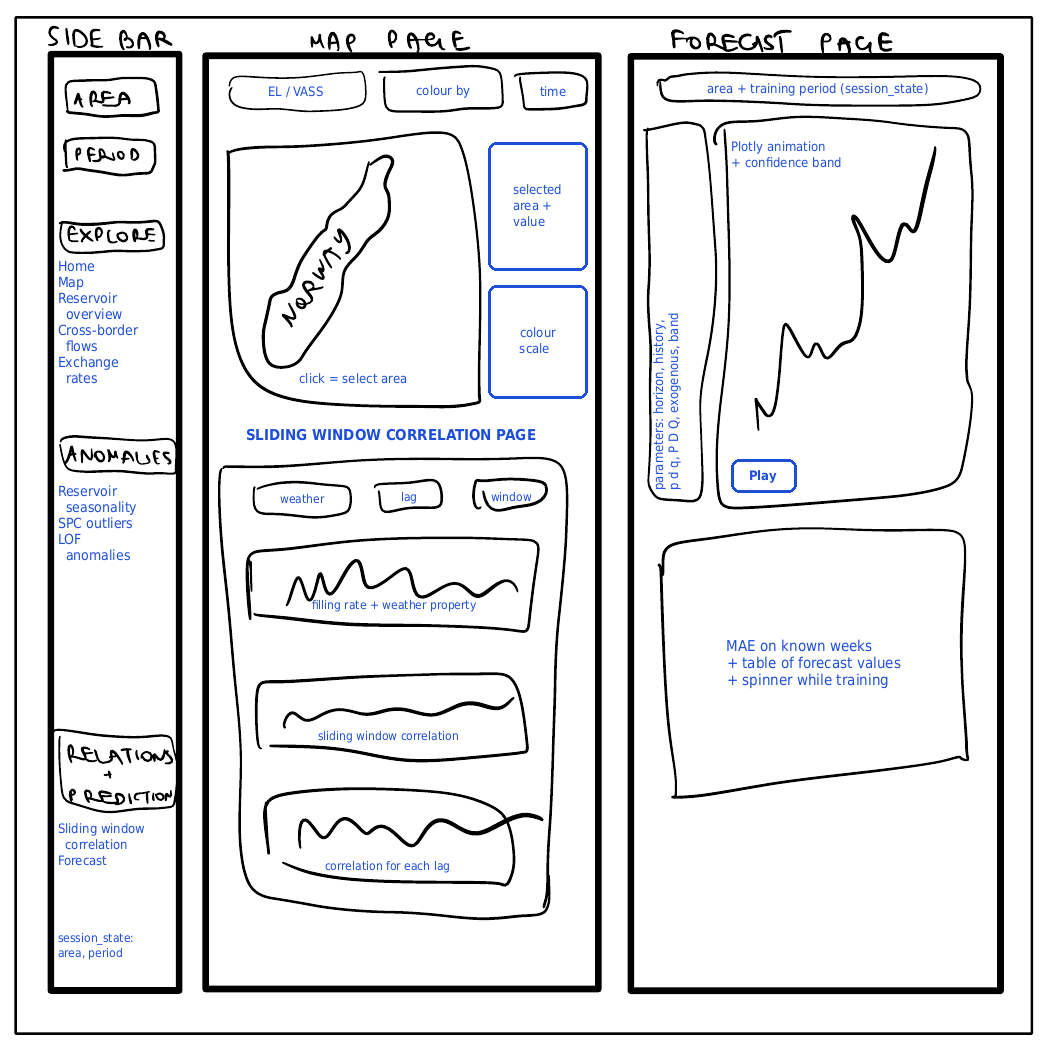